# Demo sweep with a neutral prompt (no hint about the operations) — k = 2, `openai/gpt-6-luna`

**The prompt says nothing about the operations**: not which operations exist, not how many steps the
transformation has, nothing about shifts, rotations or mirrors. It only says that every example applies the same
hidden transformation. (Notebooks 46 / 47 listed the operations A, B, C in the prompt; those results are the
"with hint" condition.)

Exact prompt (with n examples):
```
Each example below shows a 6x6 grid of digits (Input) and the grid obtained by applying the same hidden transformation to it (Output). The transformation is the same for every example.

Example 1
Input:
<6 x 6 digits>
Output:
<6 x 6 digits>
...

Apply the same transformation to this grid:
<6 x 6 digits>

<final instruction>
```
Two experiments, differing only in the final instruction:
* `answer`: "Give your answer as a 6x6 grid of digits … between <answer> and </answer>."
* `describe`: "First, describe the transformation in words, between <rule> and </rule>. Then give your answer as …"

The transformations are the 6 ordered pairs AB, AC, BA, BC, CA, CB (hidden from the model). Demos: 1, 2, 3, 5, 8, 10
(nested: n demos = the first n of 10; the first demo alone determines the transformation). 2 replicates × 120 tasks
× 2 experiments × 6 demo counts = **2,880 calls** (~$2–3).

Scoring: the answer grid is scored exactly, and wrong answers are matched against the 288 transformations. The free-
text rule is saved, together with a heuristic list of operation words it mentions (for browsing, not scoring).

Uses the `OPENROUTER_API_KEY` Colab secret. Cell 4 = dry run (no cost). Cell 5 = 4-call pilot. Cell 6 = full run
(resumable). Cell 7 = plots and tables (downloads a zip).


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: d38858850e64311d270aee1d742a9d76ec86683a


In [2]:
# --- 3. Configuration ---------------------------------------------------------------------------------------------
MODEL = "openai/gpt-6-luna"
DEMO_COUNTS = [1, 2, 3, 5, 8, 10]
REPLICATES = [0,]              # task seeds 100 + r: fresh grids per replicate
N_PER_WORD = 20
HINT = False                     # never tell the model which operations exist
EXPERIMENTS = ["answer", "describe"]
REASONING = None                 # None = the model's default (as in notebook 46)
MAX_TOKENS = None
WORKERS = 64
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
if IN_COLAB and not os.environ.get("OPENROUTER_API_KEY"):
    from google.colab import userdata
    os.environ["OPENROUTER_API_KEY"] = userdata.get("OPENROUTER_API_KEY")      # never printed
print("OpenRouter key present:", bool(os.environ.get("OPENROUTER_API_KEY")))
import json, pathlib
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 300); pd.set_option("display.width", 220)
from decompositionality import icl_api as IA
_tag = "default" if not REASONING else "_".join(f"{k}{v}" for k, v in REASONING.items())
OUT_DIR = pathlib.Path(RESULTS_ROOT) / "icl_api" / f"k2_demo_sweep_nohint_{MODEL.replace('/', '_')}_{_tag}"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("results ->", OUT_DIR)


Mounted at /content/drive
OpenRouter key present: True
results -> /content/drive/MyDrive/decompositionality_results/icl_api/k2_demo_sweep_nohint_openai_gpt-6-luna_default


In [3]:
# --- 4. Dry run: build the nested tasks; show the prompt sizes (no API calls) ------------------------------------------
BASE = {r: IA.make_nested_tasks(IA.K2_WORDS, n_per_word=N_PER_WORD, max_demos=max(DEMO_COUNTS), seed=100 + r)
        for r in REPLICATES}
(OUT_DIR / "tasks.json").write_text(json.dumps({str(r): t for r, t in BASE.items()}))
for n in DEMO_COUNTS:
    p = IA.build_prompt(IA.with_demos(BASE[REPLICATES[0]], n)[0], "describe", HINT)
    print(f"{n:2d} demos: prompt of {len(p)} characters")
print("\nExample prompt with 2 demos, experiment 'describe':\n")
print(IA.build_prompt(IA.with_demos(BASE[REPLICATES[0]], 2)[0], "describe", HINT))
PATHS = IA.sweep_paths(OUT_DIR, DEMO_COUNTS, REPLICATES)
print("\ncalls planned:", len(PATHS) * len(EXPERIMENTS) * len(BASE[REPLICATES[0]]))


 1 demos: prompt of 681 characters
 2 demos: prompt of 851 characters
 3 demos: prompt of 1021 characters
 5 demos: prompt of 1361 characters
 8 demos: prompt of 1871 characters
10 demos: prompt of 2212 characters

Example prompt with 2 demos, experiment 'describe':

Each example below shows a 6x6 grid of digits (Input) and the grid obtained by applying the same hidden transformation to it (Output). The transformation is the same for every example.

Example 1
Input:
7 0 8 4 8 9
6 4 6 7 8 8
1 1 8 3 8 9
1 4 9 0 2 5
2 5 5 3 3 3
0 5 9 3 6 6
Output:
6 3 5 9 8 9
0 2 1 1 6 7
5 5 4 1 4 0
9 5 9 8 6 8
3 3 0 3 7 4
6 3 2 8 8 8

Example 2
Input:
4 2 3 9 0 5
6 4 5 7 6 0
3 3 8 1 9 5
8 2 8 2 3 3
9 1 7 0 7 2
6 5 9 6 3 9
Output:
9 2 3 5 0 5
6 9 8 3 6 4
5 1 2 3 4 2
9 7 8 8 5 3
6 0 2 1 7 9
3 7 3 9 6 0

Apply the same transformation to this grid:
8 1 3 4 1 0
7 5 7 4 8 6
0 7 8 4 9 9
5 5 3 3 1 5
7 7 9 5 8 6
7 4 4 3 4 8

First, describe the transformation in words, between <rule> and </rule>.
Then give your a

In [4]:
# --- 5. Pilot: 4 calls with 10 demos (the longest prompts) ----------------------------------------------------------
r0, nmax = REPLICATES[0], max(DEMO_COUNTS)
IA.run(IA.with_demos(BASE[r0], nmax), PATHS[(r0, nmax)], MODEL, experiments=EXPERIMENTS, hint=HINT, reasoning=REASONING,
       max_tokens=MAX_TOKENS, workers=WORKERS, limit=4)
display(IA.score(IA.with_demos(BASE[r0], nmax), PATHS[(r0, nmax)]))


0 calls already done; 4 to run (model openai/gpt-6-luna)
  4/4 calls finished (4 ok)


,task_id,word,experiment,parsed,correct,applied,error_type,prompt_tokens,completion_tokens,reasoning_tokens,cost_usd,rule,rule_keywords,wrong_cells
0,AB-001,AB,answer,True,True,AB,correct,1679,3110,3026,0.001765,NaN,NaN,NaN
1,AB-001,AB,describe,True,True,AB,correct,1696,4681,4553,0.002552,Read each input column from bottom to top to m...,,NaN
2,AB-000,AB,describe,True,False,not a legal transform,other wrong grid,1696,8415,8286,0.004419,There isn’t enough information to determine a ...,,34.0
3,AB-000,AB,answer,True,False,not a legal transform,other wrong grid,1679,12768,12684,0.006594,NaN,NaN,30.0


In [5]:
# --- 6. Full sweep (resumable: calls already saved are skipped) ------------------------------------------------------
for r in REPLICATES:
    for n in DEMO_COUNTS:
        print(f"\n=== replicate {r}, {n} demos ===")
        IA.run(IA.with_demos(BASE[r], n), PATHS[(r, n)], MODEL, experiments=EXPERIMENTS, hint=HINT, reasoning=REASONING,
               max_tokens=MAX_TOKENS, workers=WORKERS)



=== replicate 0, 1 demos ===
0 calls already done; 240 to run (model openai/gpt-6-luna)
  10/240 calls finished (10 ok)
  20/240 calls finished (20 ok)
  30/240 calls finished (30 ok)
  40/240 calls finished (40 ok)
  50/240 calls finished (50 ok)
  60/240 calls finished (60 ok)
  70/240 calls finished (70 ok)
  80/240 calls finished (80 ok)
  90/240 calls finished (90 ok)
  100/240 calls finished (100 ok)
  110/240 calls finished (110 ok)
  120/240 calls finished (120 ok)
  130/240 calls finished (130 ok)
  140/240 calls finished (140 ok)
  150/240 calls finished (150 ok)
  160/240 calls finished (160 ok)
  170/240 calls finished (170 ok)
  180/240 calls finished (180 ok)
  190/240 calls finished (190 ok)
  200/240 calls finished (200 ok)
  210/240 calls finished (210 ok)
  220/240 calls finished (220 ok)
  230/240 calls finished (230 ok)
  240/240 calls finished (240 ok)

=== replicate 0, 2 demos ===
0 calls already done; 240 to run (model openai/gpt-6-luna)
  10/240 calls finished 

scored calls: 1440

Accuracy (mean over transformations and replicates):


experiment,answer,describe
n_demos,,
1,0.733,0.883
2,0.867,0.867
3,0.892,0.825
5,0.833,0.808
8,0.842,0.817
10,0.808,0.783



Accuracy by replicate:


,experiment,answer,describe
n_demos,replicate,,
1,0,0.733,0.883
2,0,0.867,0.867
3,0,0.892,0.825
5,0,0.833,0.808
8,0,0.842,0.817
10,0,0.808,0.783



Accuracy by transformation:


experiment answer                               describe                              
n_demos        1     2     3     5     8     10       1     2     3     5     8     10
word                                                                                  
AB           0.25  0.85  0.85  0.70  0.60  0.55     0.70  0.80  0.70  0.65  0.45  0.45
AC           0.95  1.00  1.00  1.00  1.00  1.00     1.00  1.00  1.00  1.00  1.00  1.00
BA           0.80  0.85  0.95  0.75  0.85  0.70     0.85  0.90  0.90  0.80  0.80  0.75
BC           1.00  1.00  1.00  1.00  1.00  1.00     1.00  1.00  1.00  1.00  1.00  1.00
CA           0.75  0.90  0.95  0.90  0.95  0.95     0.95  0.85  0.70  0.75  0.90  0.85
CB           0.65  0.60  0.60  0.65  0.65  0.65     0.80  0.65  0.65  0.65  0.75  0.65

... (4 outputs left out)


'describe': operation words mentioned in the rule (heuristic), by transformation:


,word,rule_keywords,count
0,AB,,45
5,AB,rotate,44
2,AB,reverse,12
1,AB,reflect,5
9,AC,reverse,120
15,BA,transpose,40
16,BA,transpose > reverse,35
10,BA,,21
11,BA,reverse,11
20,BC,transpose,117



A few rules per transformation (3 demos, replicate 0):

AB:
  - Rotate the grid 90° clockwise, then move the last row of the rotated grid to the top.
  - Rotate the grid 90° clockwise, then move the bottom row to the top.
  - Read the input columns from bottom to top, starting with the rightmost column and then moving left, wrapping around to the first column.

AC:
  - Reverse the order of the first five digits in each row, leaving the sixth digit unchanged.
  - Reverse the first five digits in each row, leaving the sixth digit unchanged.
  - Reverse the first five digits in each row, leaving the sixth digit unchanged.

BA:
  - Transpose the grid: each output row is the corresponding column of the input.
  - Transpose the grid, then keep the first digit in each row fixed and reverse the order of the remaining five digits.
  - Transpose the grid: each output row is the corresponding column of the input, read from top to bottom.

BC:
  - Transpose the grid: turn each column of the input

,prompt_tokens,completion_tokens,reasoning_tokens,cost_usd
total,1298548.0,3234219.0,3094312.0,1.765354


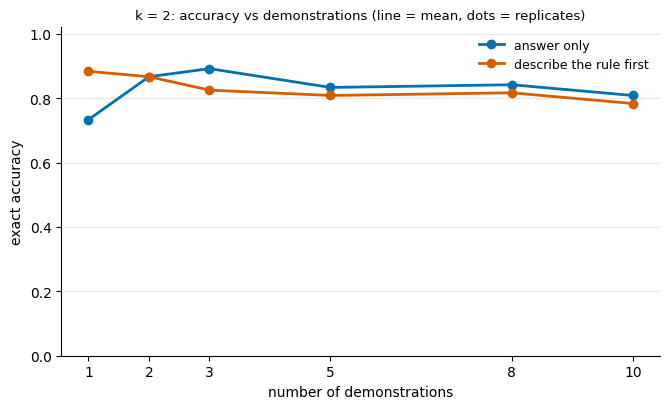

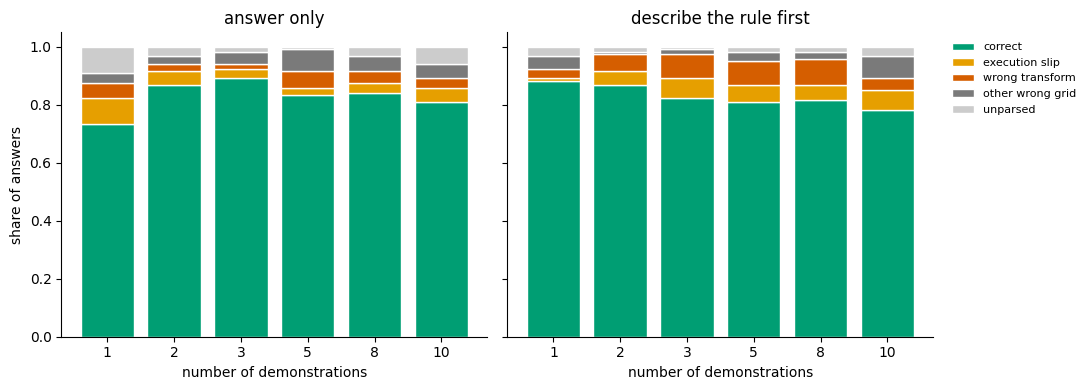

saved to /content/drive/MyDrive/decompositionality_results/icl_api/k2_demo_sweep_nohint_openai_gpt-6-luna_default


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# --- 7. Plots and tables ----------------------------------------------------------------------------------------------
df = IA.score_sweep(BASE, OUT_DIR, DEMO_COUNTS, REPLICATES)
print("scored calls:", len(df))
acc = df.pivot_table(index="n_demos", columns="experiment", values="correct", aggfunc="mean").round(3)
print("\nAccuracy (mean over transformations and replicates):"); display(acc)
print("\nAccuracy by replicate:"); display(df.pivot_table(index=["n_demos", "replicate"], columns="experiment",
                                                          values="correct", aggfunc="mean").round(3))
print("\nAccuracy by transformation:"); display(df.pivot_table(index="word", columns=["experiment", "n_demos"],
                                                               values="correct", aggfunc="mean").round(2))
print("\nError types (share of answers):")
display(df.groupby(["experiment", "n_demos"]).error_type.value_counts(normalize=True).unstack(fill_value=0).round(3))
print("\nWrong legal transforms (what was applied instead):")
w = df[df.error_type == "wrong transform"]
display(w.groupby(["word", "applied"]).size().rename("count").reset_index().sort_values("count", ascending=False))
d = df[df.experiment == "describe"]
print("\n'describe': operation words mentioned in the rule (heuristic), by transformation:")
display(d.groupby(["word", "rule_keywords"]).size().rename("count").reset_index()
        .sort_values(["word", "count"], ascending=[True, False]).groupby("word").head(4))
print("\nA few rules per transformation (3 demos, replicate 0):")
for w_, g_ in d[(d.n_demos == 3) & (d.replicate == REPLICATES[0])].groupby("word"):
    print(f"\n{w_}:"); [print("  -", str(x)[:220].replace("\n", " ")) for x in g_.rule.head(3)]
print("\nUsage:"); display(df[["prompt_tokens", "completion_tokens", "reasoning_tokens", "cost_usd"]]
                           .apply(pd.to_numeric, errors="coerce").sum().to_frame("total").T)
figs = IA.plot_sweep(df, OUT_DIR)
df.to_csv(OUT_DIR / "scores.csv", index=False)
print("saved to", OUT_DIR)
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)
    files.download(str(OUT_DIR) + ".zip")
